In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#importing thr important libraries for data cleaning and visualization  

In [2]:
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", None)

#display options

In [3]:
df_raw = pd.read_csv("yoruba_proverbs_clean.csv")

#import the scraped data from the csv file

In [4]:
df = df_raw.copy()

#creating a copy of the raw data to work with

In [5]:
df.head()

,entry_id,part_id,part_code,part_theme,letter,yoruba,english_literal,interpretation_gold,notes,source_url
0,a1845a38747df71e,1,1a,"humility, self-control, self-knowledge, self-respect, self-restraint",A,A di gàárì sílẹ̀ ewúrẹ́ ńyọjú; ẹrù ìran rẹ̀ ni?,"We prepare the saddle, and the goat presents itself; is it a burden for the lineage of goats?",Goats that know their place do not offer their backs to be saddled.,NaN,https://yoruba.unl.edu/yoruba.php-text=1a&view=0&uni=0&l=1.htm
1,d1028fe117c17f87,1,1a,"humility, self-control, self-knowledge, self-respect, self-restraint",A,This is a variant of A gbé gàárì ọmọ ewúrẹ́ ńrojú . . .,NaN,NaN,NaN,https://yoruba.unl.edu/yoruba.php-text=1a&view=0&uni=0&l=1.htm
2,a6223c8a370d0dd5,1,1a,"humility, self-control, self-knowledge, self-respect, self-restraint",A,A fi ọ́ jọba ò ńṣàwúre o fẹ́ jẹ Ọlọ́run ni?,"You have been crowned a king, and yet you make good-luck charms; would you be crowned God?",Being crowned a king is about the best fortune a mortal could hope for.,NaN,https://yoruba.unl.edu/yoruba.php-text=1a&view=0&uni=0&l=1.htm
3,c088fcb6062ca2a7,1,1a,"humility, self-control, self-knowledge, self-respect, self-restraint",A,"A fijó gba Awà; a fìjà gba Awà; bí a ò bá jó, bí a ò bá jà, bí a bá ti gba Awà, kò tán bí?",NaN,NaN,NaN,https://yoruba.unl.edu/yoruba.php-text=1a&view=0&uni=0&l=1.htm
4,c35f4b8d772e1ba1,1,1a,"humility, self-control, self-knowledge, self-respect, self-restraint",A,"By dancing we take possession of Awà; through fighting we take possession of Awà; if we neither dance nor fight, but take possession of Awà anyway, is the result not the same?",(Why make a huge production of a matter that is easily taken care of?),NaN,NaN,https://yoruba.unl.edu/yoruba.php-text=1a&view=0&uni=0&l=1.htm


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3286 entries, 0 to 3285
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   entry_id             3286 non-null   object
 1   part_id              3286 non-null   int64 
 2   part_code            3286 non-null   object
 3   part_theme           3286 non-null   object
 4   letter               2613 non-null   object
 5   yoruba               3286 non-null   object
 6   english_literal      2810 non-null   object
 7   interpretation_gold  2294 non-null   object
 8   notes                678 non-null    object
 9   source_url           3286 non-null   object
dtypes: int64(1), object(9)
memory usage: 256.8+ KB


In [7]:
df = df.drop(columns=["source_url", "notes"], errors="ignore")

#dropping the source_url and notes column as it is not needed for analysis

In [8]:
df = df.rename(columns={
    "yoruba": "proverb_yoruba",
    "english_literal": "translation_english",
    "interpretation_gold": "interpretation_english",
    "part_id": "part_num"
})

#renaming the columns to more descriptive names

In [9]:
df.columns

Index(['entry_id', 'part_num', 'part_code', 'part_theme', 'letter',
       'proverb_yoruba', 'translation_english', 'interpretation_english'],
      dtype='object')

In [10]:
text_cols = [
    "proverb_yoruba",
    "translation_english",
    "interpretation_english",
    "part_theme"
]

for col in ["proverb_yoruba", "translation_english", "interpretation_english", "part_theme"]:
    df[col] = df[col].astype("string").str.strip()

    #stripping whitespace from the text columns

In [11]:
df[text_cols + ["part_num"]].isna().sum()

#view the number of missing values in the text columns and part_num column

proverb_yoruba              0
translation_english       476
interpretation_english    992
part_theme                  0
part_num                    0
dtype: int64

In [12]:
for col in text_cols:
    print(col, (df[col] == "").sum())

#view the number of empty strings in the text columns

proverb_yoruba 0
translation_english 0
interpretation_english 0
part_theme 0


In [13]:
df = df.replace({"nan": np.nan, "NaN": np.nan, "None": np.nan, "": np.nan})

#replacing common string representations of missing values with actual NaN values

In [14]:
df = df.replace(r"^\s*$", np.nan, regex=True)

#replacing any remaining empty strings with NaN values

In [15]:
required_cols = [
    "proverb_yoruba",
    "translation_english",
    "interpretation_english",
    "part_num"
]

#creating a list of required columns for analysis and quality flagging

In [16]:
df["quality_flag"] = "OK"

for col in required_cols:
    df.loc[df[col].isna(), "quality_flag"] = f"MISSING_{col.upper()}"

#creating a quality flag column to indicate which rows have missing values in the required columns

In [17]:
df["quality_flag"].value_counts()

#view the distribution of quality flags in the dataset

quality_flag
OK                                2294
MISSING_INTERPRETATION_ENGLISH     992
Name: count, dtype: int64

In [ ]:
eval_df = df.dropna(subset=[
    "proverb_yoruba",
    "translation_english",
    "interpretation_english"
    ]).copy()

print("Evaluation rows:", eval_df.shape)

Evaluation rows: (2274, 9)


In [29]:
# normalize
eval_df["proverb_yoruba"] = (
    eval_df["proverb_yoruba"].astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# keep best version (longest interpretation)
eval_df["interp_len"] = eval_df["interpretation_english"].astype("string").str.len()
eval_df = eval_df.sort_values(["proverb_yoruba", "interp_len"], ascending=[True, False])
eval_df = eval_df.drop_duplicates(subset=["proverb_yoruba"], keep="first").copy()
eval_df = eval_df.drop(columns=["interp_len"])

print("FINAL eval_df:", eval_df.shape)

FINAL eval_df: (2272, 9)


In [30]:
yoruba_chars = ["ẹ", "ọ", "ṣ"]

eval_df["has_yoruba_diacritics"] = eval_df["proverb_yoruba"].apply(
    lambda x: any(ch in x for ch in yoruba_chars)
)

eval_df["has_yoruba_diacritics"].value_counts(normalize=True)

#checking how many proverbs contain Yoruba diacritics to assess the quality of the data and determine if additional cleaning is needed to add diacritics to the proverbs that are missing them

has_yoruba_diacritics
True     0.755282
False    0.244718
Name: proportion, dtype: float64

In [31]:
df_clean = eval_df[eval_df["quality_flag"] == "OK"].copy()

In [32]:
print("Original size:", len(df))
print("Clean size:", len(df_clean))


Original size: 3257
Clean size: 2272


In [33]:
# 1) Ensure text columns are proper pandas strings (preserves NaN)
for col in ["proverb_yoruba", "translation_english", "interpretation_english", "part_theme"]:
    df[col] = df[col].astype("string").str.strip()  

# 2) Keep only rows with BOTH translation + interpretation
df_clean = df[
    df["translation_english"].notna() &
    df["interpretation_english"].notna()
].copy()

print("Original rows:", len(df))
print("After requiring translation+interpretation:", len(df_clean))
print("Dropped rows:", len(df) - len(df_clean))

Original rows: 3257
After requiring translation+interpretation: 2274
Dropped rows: 983


In [34]:
dup_mask = df_clean.duplicated(subset=["proverb_yoruba"], keep=False)
print("Duplicate proverb_yoruba rows:", dup_mask.sum())

df_clean.loc[dup_mask, ["proverb_yoruba", "translation_english", "interpretation_english", "part_num", "part_code"]].sort_values("proverb_yoruba").head(30)

Duplicate proverb_yoruba rows: 4


,proverb_yoruba,translation_english,interpretation_english,part_num,part_code
1448,Ojú kan làdá ńní.,A cutlass has only one edge.,One should concentrate on one matter at a time.,2,1b
2225,Ojú kan làdá ńní.,A machete can have only one edge.,"One should be true to one calling or relationship, and not philander.",3,1c
2493,Àgbẹ̀ gbóko róṣù.,A farmer remains on the farm and sees the moon.,The conscientious farmer spends long periods on the farm; persistence in the key to success.,4,1d
2940,Àgbẹ̀ gbóko róṣù.,A farmer stays on the farm and sees the moon.,The conscientious farmer spends long periods on the farm; persistence is the key to success.,5,1e


In [38]:
# Ensure no empties slipped through
assert df_clean["translation_english"].notna().all()
assert df_clean["interpretation_english"].notna().all()

# Check part distribution didn't get distorted
print(df_clean["part_num"].value_counts().sort_index())

# Confirm dataset uniqueness (depending on chosen dedupe strategy)
print("Unique proverbs:", df_clean["proverb_yoruba"].nunique())
print("Total rows:", len(df_clean))


part_num
1    492
2    620
3    564
4    326
5    190
6     82
Name: count, dtype: int64
Unique proverbs: 2272
Total rows: 2274


C:\Users\temisola\AppData\Local\Temp\ipykernel_27552\1398925396.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="part_num", data=df_clean, palette="viridis")


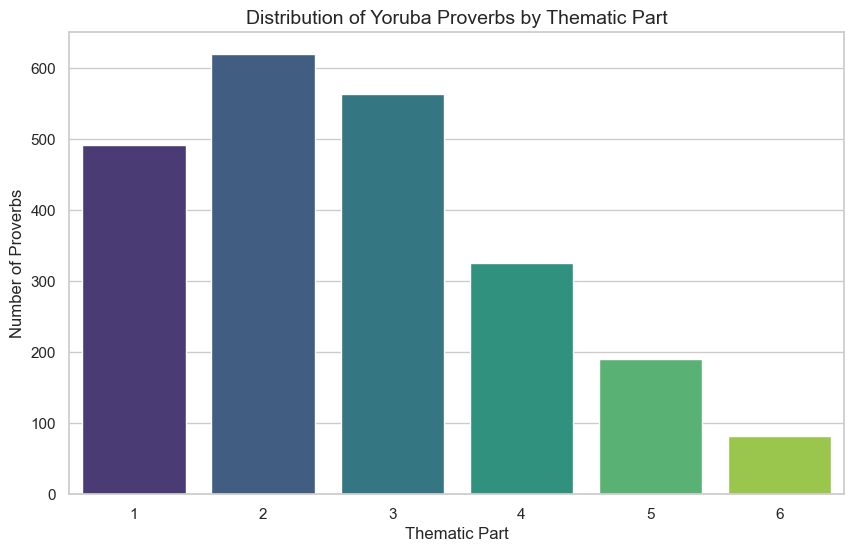

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plt.figure(figsize=(10,6))
sns.countplot(x="part_num", data=df_clean, palette="viridis")

plt.title("Distribution of Yoruba Proverbs by Thematic Part", fontsize=14)
plt.xlabel("Thematic Part")
plt.ylabel("Number of Proverbs")

plt.show()


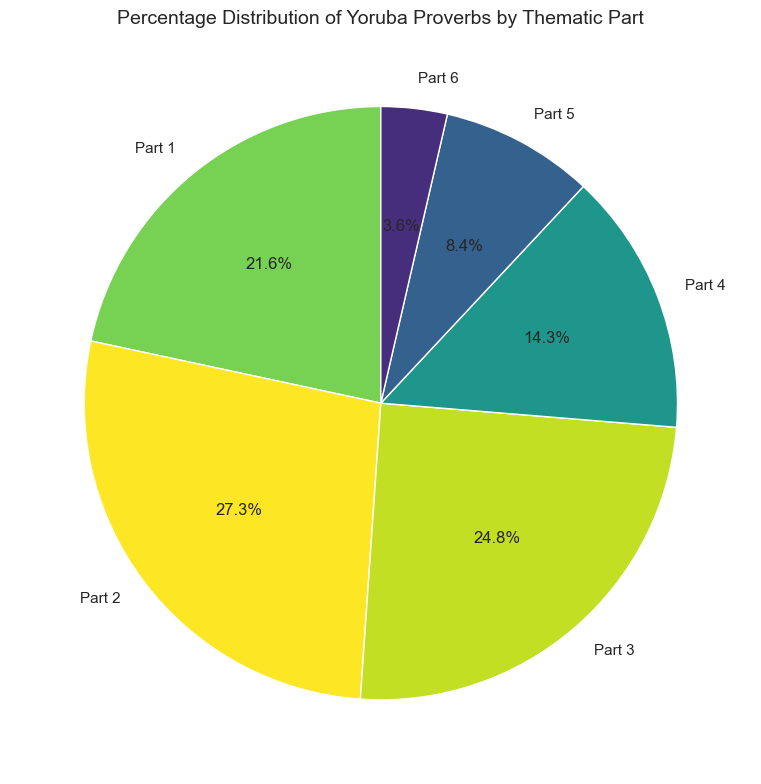

In [40]:
part_counts = df_clean["part_num"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(8,8))

plt.pie(
    part_counts.values,
    labels=[f"Part {i}" for i in part_counts.index],
    autopct='%1.1f%%',
    startangle=90,
    colors=plt.cm.viridis(part_counts.values / max(part_counts.values))
)

plt.title("Percentage Distribution of Yoruba Proverbs by Thematic Part", fontsize=14)

plt.tight_layout()
plt.show()

In [41]:
# Word count (split by whitespace)
df_clean["yoruba_word_len"] = df_clean["proverb_yoruba"].str.split().str.len()
df_clean["translation_word_len"] = df_clean["translation_english"].str.split().str.len()
df_clean["interpretation_word_len"] = df_clean["interpretation_english"].str.split().str.len()

C:\Users\temisola\AppData\Local\Temp\ipykernel_27552\3730589735.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


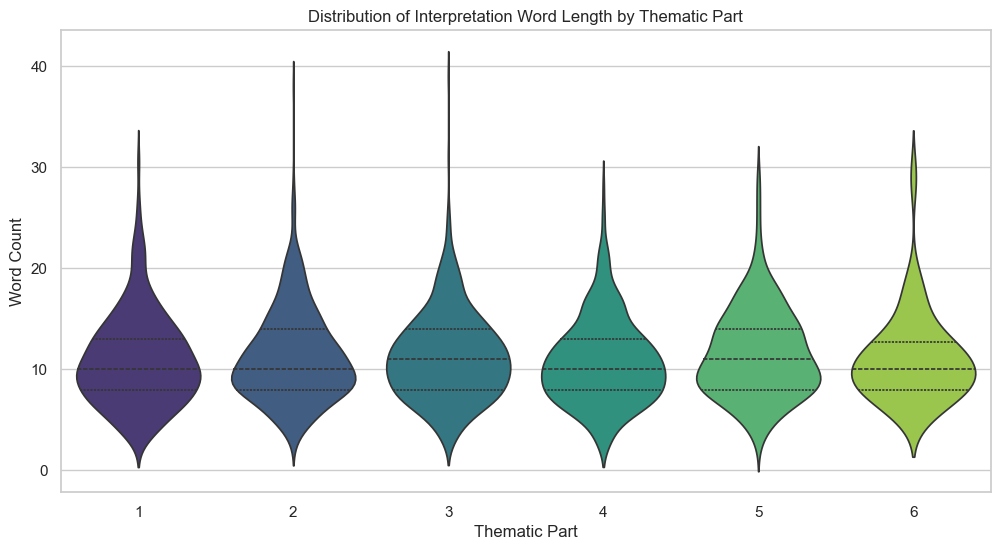

In [42]:
plt.figure(figsize=(12,6))

sns.violinplot(
    x="part_num",
    y="interpretation_word_len",
    data=df_clean,
    inner="quartile",
    palette="viridis"
)

plt.title("Distribution of Interpretation Word Length by Thematic Part")
plt.xlabel("Thematic Part")
plt.ylabel("Word Count")

plt.show()

C:\Users\temisola\AppData\Local\Temp\ipykernel_27552\1024662193.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mean_lengths.index, y=mean_lengths.values, palette="viridis")


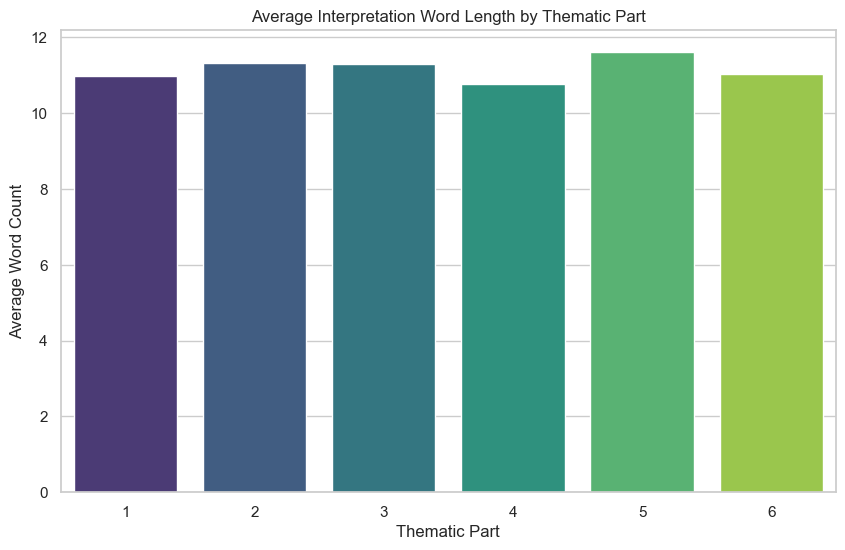

In [43]:
mean_lengths = df_clean.groupby("part_num")["interpretation_word_len"].mean()

plt.figure(figsize=(10,6))
sns.barplot(x=mean_lengths.index, y=mean_lengths.values, palette="viridis")

plt.title("Average Interpretation Word Length by Thematic Part")
plt.xlabel("Thematic Part")
plt.ylabel("Average Word Count")

plt.show()


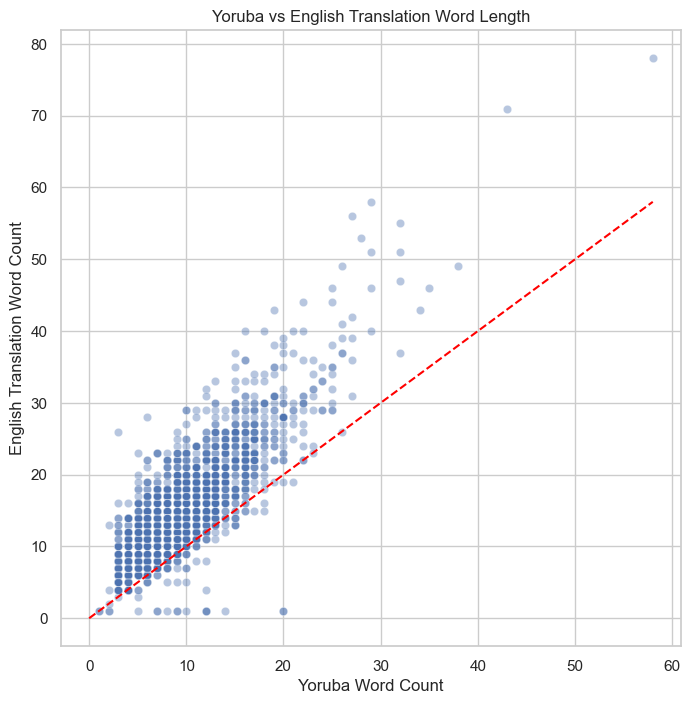

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,8))

sns.scatterplot(
    x="yoruba_word_len",
    y="translation_word_len",
    data=df_clean,
    alpha=0.4
)

plt.plot([0, df_clean["yoruba_word_len"].max()],
         [0, df_clean["yoruba_word_len"].max()],
         color="red", linestyle="--")

plt.title("Yoruba vs English Translation Word Length")
plt.xlabel("Yoruba Word Count")
plt.ylabel("English Translation Word Count")

plt.show()

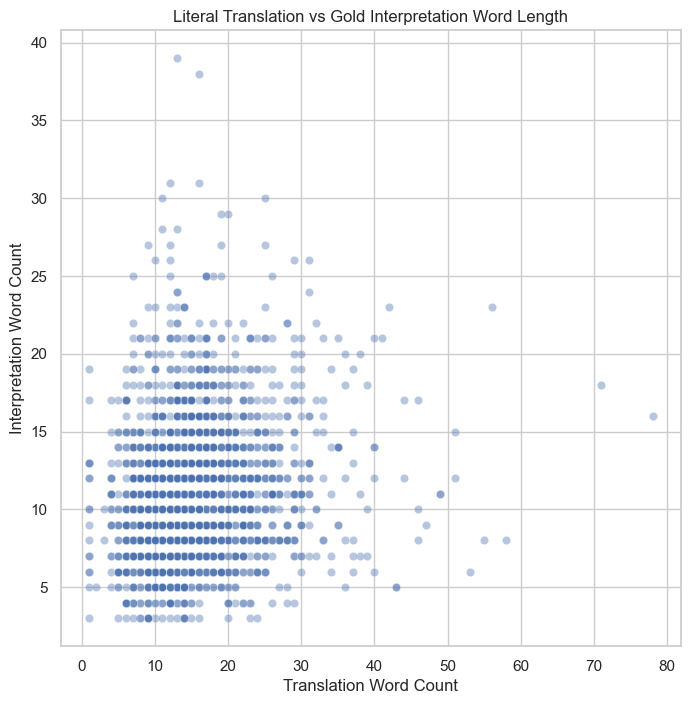

In [45]:
plt.figure(figsize=(8,8))

sns.scatterplot(
    x="translation_word_len",
    y="interpretation_word_len",
    data=df_clean,
    alpha=0.4
)

plt.title("Literal Translation vs Gold Interpretation Word Length")
plt.xlabel("Translation Word Count")
plt.ylabel("Interpretation Word Count")

plt.show()


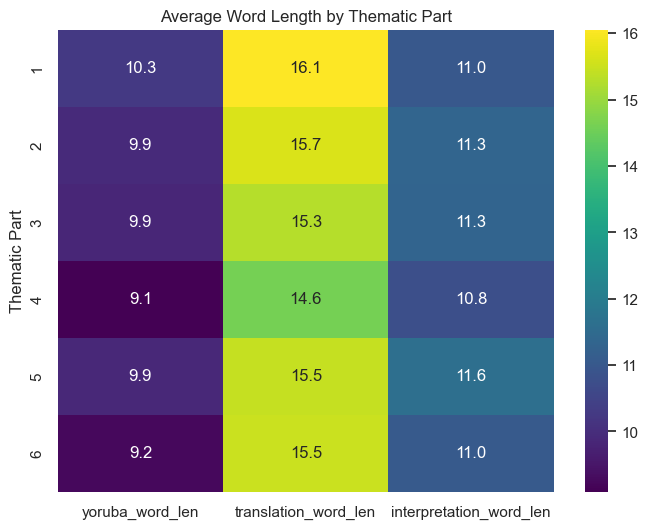

In [46]:
import pandas as pd

length_summary = df_clean.groupby("part_num")[[
    "yoruba_word_len",
    "translation_word_len",
    "interpretation_word_len"
]].mean()

plt.figure(figsize=(8,6))
sns.heatmap(length_summary, annot=True, cmap="viridis", fmt=".1f")

plt.title("Average Word Length by Thematic Part")
plt.ylabel("Thematic Part")
plt.show()


we can see that the yoruba words are a lot shorter than translated and interpretative word lengths. 

In [53]:
# Show a few Yoruba examples in notebook
display(df_clean[["proverb_yoruba"]].head(20))

,proverb_yoruba
0,A di gàárì sílẹ̀ ewúrẹ́ ńyọjú; ẹrù ìran rẹ̀ ni?
2,A fi ọ́ jọba ò ńṣàwúre o fẹ́ jẹ Ọlọ́run ni?
5,A gbé gàárì ọmọ ewurẹ ńrojú; kì í ṣe ẹrù àgùntàn.
7,A kì í bá ọba pàlà kí ọkọ́ ọba má ṣàn-ánni lẹ́sẹ̀.
8,A kì í bínú ààtàn ká dalẹ̀ sígbẹ̀ẹ́.
9,A kì í bínú orí ká fi fìlà dé ìbàdí.
10,A kì í bẹ̀rù ikú bẹ̀rù àrùn ká ní kí ọmọ ó kú sinni.
11,A kì í bọ òrìṣà lójú ọ̀fọ́n-ọ̀n; bó bá dalẹ́ a máa tú pẹpẹ.
12,A kì í dàgbà má làáyà; ibi ayé bá báni là ńjẹ ẹ́.
13,A kì í dá ọwọ́ lé ohun tí a ò lè gbé.


In [49]:
eval_df.to_csv("yoruba_proverbs_eval_final_utf8sig.csv", index=False, encoding="utf-8-sig")